<div align="center">

# Clustering Track - Urban Bike Demand Forecasting

</div>

---

## Problem Statement

Predict the bike rental demand for an urban bike-sharing system using information available about weather conditions, temperature, humidity, wind speed, cloud coverage, day type, and other environmental factors.

> **Note for this track.** In clustering we do not use the demand value to build the clusters. We group the hours using only weather and calendar information. After that, we use demand (`count`) just to check what the groups mean.

## Dataset

**`capitalbikeshare-complete.csv`**, containing **33,379 records and 16 original columns**. The dataset includes bike rental demand, datetime information, weather conditions, temperature, humidity, wind speed, pressure, cloud coverage, rainfall, snowfall, holiday and working-day information.

| Group | Columns | Description |
|:--|:--|:--|
| Demand | `count` | Number of bike rentals in the hour |
| Time | `datetime` | Hourly timestamp (2018-01-01 to 2021-08-31) |
| Day type | `holiday`, `workingday` | 0 / 1 flags |
| Temperature | `temp`, `feels_like`, `temp_min`, `temp_max` | Temperature values (°C) |
| Atmosphere | `pressure`, `humidity` | Air pressure and humidity (%) |
| Wind | `wind_speed`, `wind_deg` | Wind speed and wind direction (degrees) |
| Rain, snow, clouds | `rain_1h`, `snow_1h`, `clouds_all` | Rain and snow in the last hour, cloud cover (%) |
| Weather type | `weather_main` | Text label (Clouds, Rain, Clear, Mist, ...) |
| *Made in this notebook* | `count_class` | *Low / High demand, split at the median of `count`. Used only to check the clusters.* |

## Notebook Map

| Section | Contents | Rubric |
|:--:|:--|:--:|
| [1](#s1) | Load & audit | A1 |
| [2](#s2) | Exploratory data analysis | A2, A3 |
| [3](#s3) | Cleaning | B1 |
| [4](#s4) | Feature engineering | B3 |
| [5](#s5) | Encoding, scaling, splitting, PCA structure | B2 |
| [6](#s6) | K-Means (elbow) and Agglomerative (dendrogram, linkages) | B1, B2 |
| [7](#s7) | Comparative evaluation: Silhouette, Davies-Bouldin, Calinski-Harabasz, stability | B2 |
| [8](#s8) | Cluster visualisation: PCA 2D and t-SNE | B3 |
| [9](#s9) | Cluster profiling and external validation | - |
| [10](#s10) | Conclusion | - |

### Steps followed in this notebook

| Step | What we did |
|:--|:--|
| Label for checking | Made `count_class` (High / Low) using the median of `count` (236 rides per hour). It is **not used to build clusters**. |
| Cleaning | Filled blank `rain_1h` and `snow_1h` with 0. Capped very large values at the 99.9th percentile. No rows were removed. |
| Features | Used 17 features (hour, month and wind direction converted to sin / cos, rain or snow flag, temperature gap). `count` and `count_class` were left out. |
| Preparation | 80 / 20 train-test split, scaling fitted on the training data only, and a sample of 8,000 rows. |
| Models | K-Means (k chosen using elbow and silhouette) and Agglomerative clustering (4 linkages compared). |
| Evaluation | Silhouette, Davies-Bouldin, Calinski-Harabasz, stability (ARI) and silhouette on the test data. |
| Understanding the clusters | PCA 2D, t-SNE, cluster profiles and comparison with the real labels. |

> Keep `capitalbikeshare-complete.csv` in the same folder as this notebook. The random seed is 42, so the results can be repeated.

---

<a id="s1"></a>
## Section 1: Load & Audit

In this section we load the data, create the `count_class` label, and check the data quality (data types, missing values, duplicates and class balance).

- `count_class` is Low (0) or High (1), split at the median of `count`. It is the same rule as in the classification notebook.
- We use it **only after clustering** to check the results.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid', palette='colorblind')

df = pd.read_csv('capitalbikeshare-complete.csv',
                 encoding='utf-8-sig', parse_dates=['datetime'])

# Ground-truth label: SAME rule as the classification notebook
# (Low = 0, High = 1, split at the median of 'count').
# Used ONLY for validation after clustering, never for fitting.
median_count = df['count'].median()
df['count_class'] = pd.Categorical(np.where(df['count'] > median_count, 'High', 'Low'),
                                   categories=['Low', 'High'])
print("Median hourly rides:", median_count)

print("Shape:", df.shape)
print("\nDtypes:\n", df.dtypes)
print("\nMissing values:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate timestamps:", df['datetime'].duplicated().sum())
print("\nTarget (count_class) distribution:\n", df['count_class'].value_counts())
print("\nweather_main distribution:\n", df['weather_main'].value_counts())
df.describe().T

Median hourly rides: 236.0
Shape: (33379, 17)

Dtypes:
 datetime        datetime64[us]
count                    int64
holiday                  int64
workingday               int64
temp                   float64
feels_like             float64
temp_min               float64
temp_max               float64
pressure                 int64
humidity                 int64
wind_speed             float64
wind_deg                 int64
rain_1h                float64
snow_1h                float64
clouds_all               int64
weather_main               str
count_class           category
dtype: object

Missing values:
 datetime            0
count               0
holiday             0
workingday          0
temp                0
feels_like          0
temp_min            0
temp_max            0
pressure            0
humidity            0
wind_speed          0
wind_deg            0
rain_1h         26608
snow_1h         33053
clouds_all          0
weather_main        0
count_class         0
dtype: int6

,count,mean,min,25%,50%,75%,max,std
datetime,33379,2019-10-25 07:31:08.755804,2018-01-01 00:00:00,2018-11-21 12:30:00,2019-10-14 23:00:00,2020-10-08 03:30:00,2021-08-31 23:00:00,NaN
count,33379.0,333.139788,0.0,59.0,236.0,495.0,2038.0,336.519514
holiday,33379.0,0.030618,0.0,0.0,0.0,0.0,1.0,0.172283
workingday,33379.0,0.681327,0.0,0.0,1.0,1.0,1.0,0.465969
temp,33379.0,15.213087,-12.79,6.86,15.65,23.8,36.71,9.908964
feels_like,33379.0,14.994843,-18.91,5.88,15.02,24.14,43.71,11.176487
temp_min,33379.0,13.532648,-15.14,5.23,13.91,21.97,35.38,9.993094
temp_max,33379.0,16.105542,-12.29,7.73,16.59,24.39,38.81,9.984839
pressure,33379.0,1017.071602,980.0,1012.0,1017.0,1022.0,1044.0,7.37942
humidity,33379.0,67.818628,14.0,53.0,70.0,84.0,100.0,18.422105


> **Observation: data audit.**
> - The data has **33,379 rows** and 17 columns (16 original columns plus `count_class`).
> - There are no duplicate rows, but **1,963 timestamps repeat**. This means some hours have more than one weather record. They are different rows, so we keep them.
> - Only `rain_1h` (26,608 blank) and `snow_1h` (33,053 blank) have missing values. Blank means no rain or snow was recorded, so we set them to 0 in Section 3.
> - The two classes are almost equal (16,692 Low and 16,687 High) because we split at the median.
> - In `weather_main`, **Clouds (22,157)** and **Rain (5,649)** are the most common. Some types like Squall (1 row), Smoke and Haze are very rare.

---

<a id="s2"></a>
## Section 2: Exploratory Data Analysis

Here we look at the data using plots to understand each variable and how they are related. Every plot has a short observation below it.

### 2a. Distribution of every numeric feature

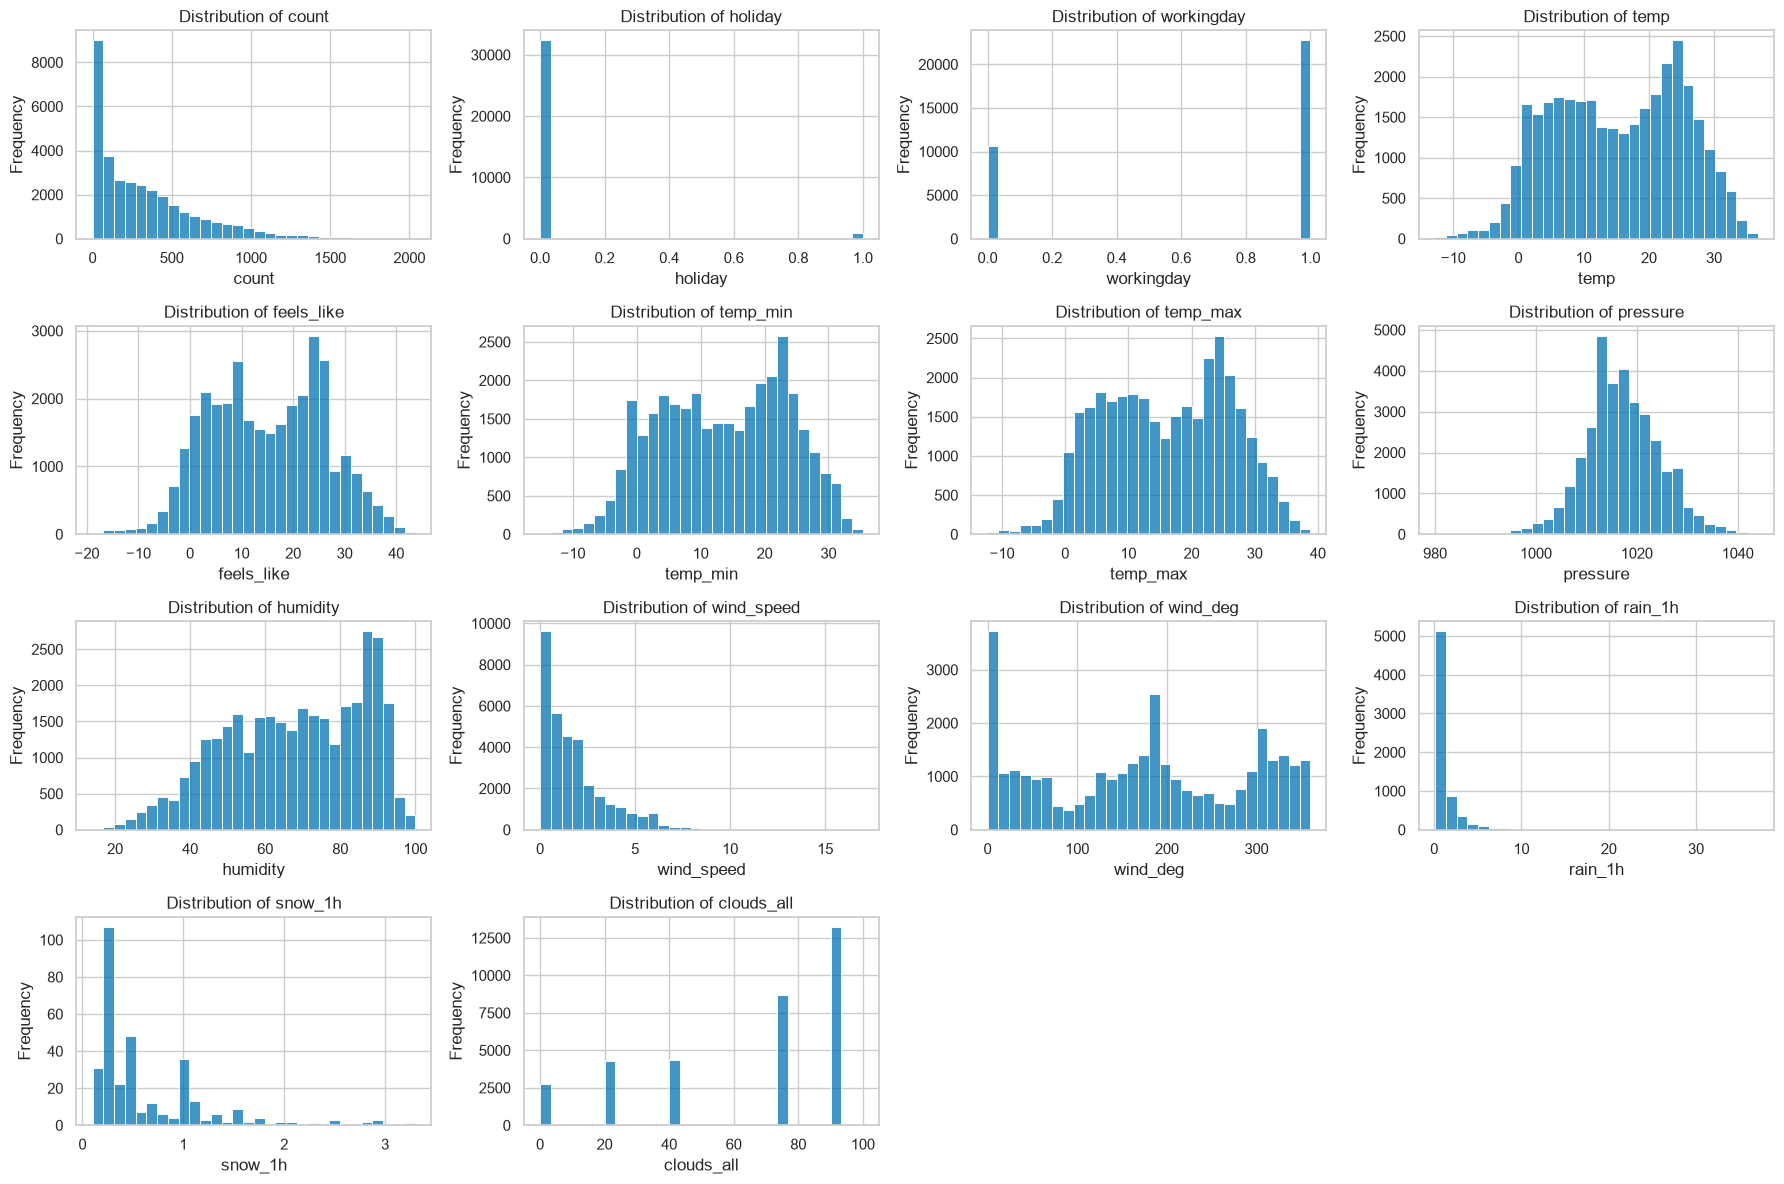

In [2]:
# 2a. Distribution of every numeric feature
num_cols = df.select_dtypes('number').columns.tolist()
fig, axes = plt.subplots(4, 4, figsize=(18, 12))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(df[c], bins=30, ax=ax)
    ax.set_title(f'Distribution of {c}'); ax.set_xlabel(c); ax.set_ylabel('Frequency')
for ax in axes.ravel()[len(num_cols):]:
    ax.axis('off')
plt.tight_layout(); plt.show()

> **Observation 2a: distributions.**
> - `count` is **skewed to the right**. About 9,000 hours have very few rentals, and only a few hours go above 1,500.
> - `temp` has **two peaks**, one around 5 to 10 °C (winter) and one around 24 °C (summer). `feels_like`, `temp_min` and `temp_max` look almost the same as `temp`.
> - `pressure` looks like a bell shape. `humidity` is mostly high, with many hours around 85 to 90%.
> - `wind_speed`, `rain_1h` and `snow_1h` are **skewed to the right** with a few very large values.
> - `clouds_all` has only a few values (0, 20, 40, 75, 90), and `wind_deg` has a spike at 0.
> - `holiday` is rare (about 3% of rows) and about two thirds of rows are working days.

### 2b. Correlation heatmap

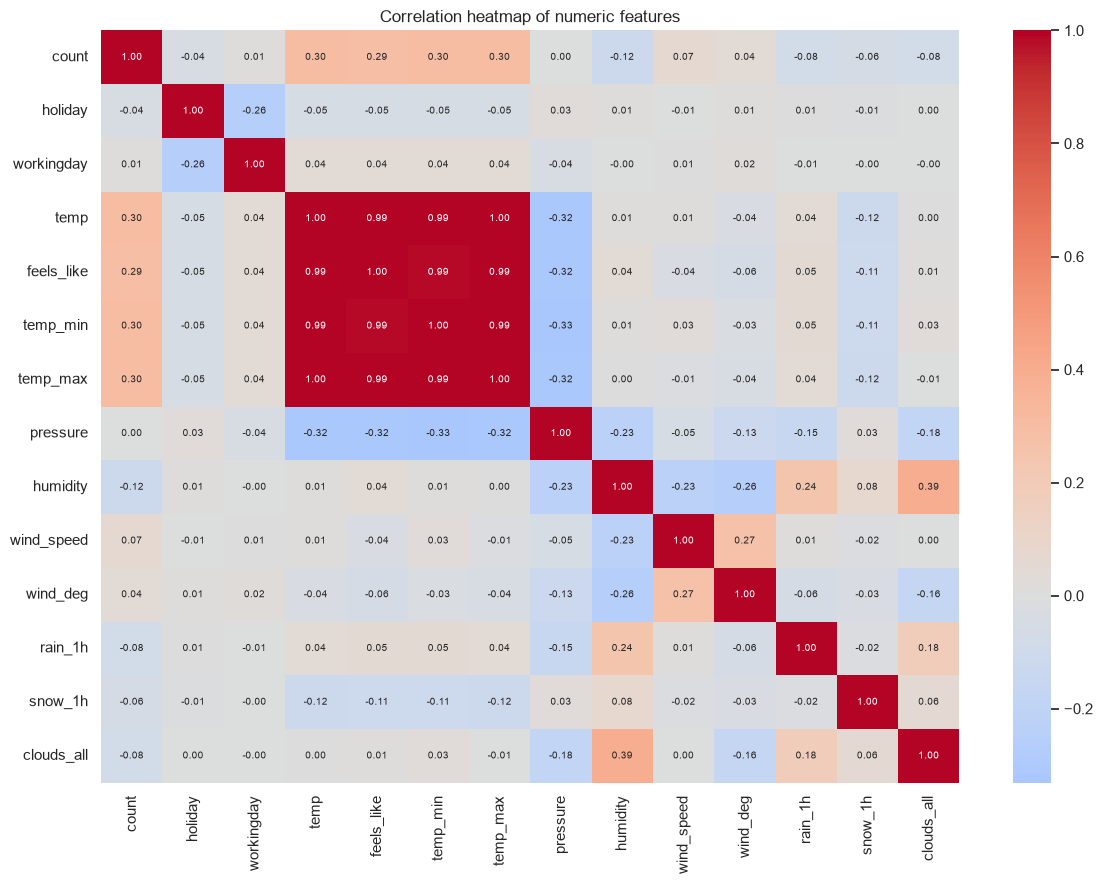

In [3]:
# 2b. Correlation heatmap
# rain_1h / snow_1h are blank when nothing was recorded -> treat as 0 so every pair has a value
corr_df = df[num_cols].copy()
corr_df[['rain_1h', 'snow_1h']] = corr_df[['rain_1h', 'snow_1h']].fillna(0)

plt.figure(figsize=(12, 9))
sns.heatmap(corr_df.corr(), annot=True, fmt='.2f', annot_kws={'size': 7},
            cmap='coolwarm', center=0)
plt.title('Correlation heatmap of numeric features'); plt.tight_layout(); plt.show()

> **Observation 2b: correlations.**
> - `temp`, `feels_like`, `temp_min` and `temp_max` are almost the same (correlation **0.99 to 1.00**). If we keep all of them, temperature will get too much weight in clustering, so we keep only one in Section 4.
> - `count` is most related to temperature (**about 0.30**) and slightly negative with humidity (-0.12). The other weather columns are close to 0, so **weather alone explains only a small part of demand**.
> - `humidity` and `clouds_all` are somewhat related (0.39), and `pressure` and temperature are negatively related (-0.32). No other pair is strongly related.

### 2c. Target and weather type distribution

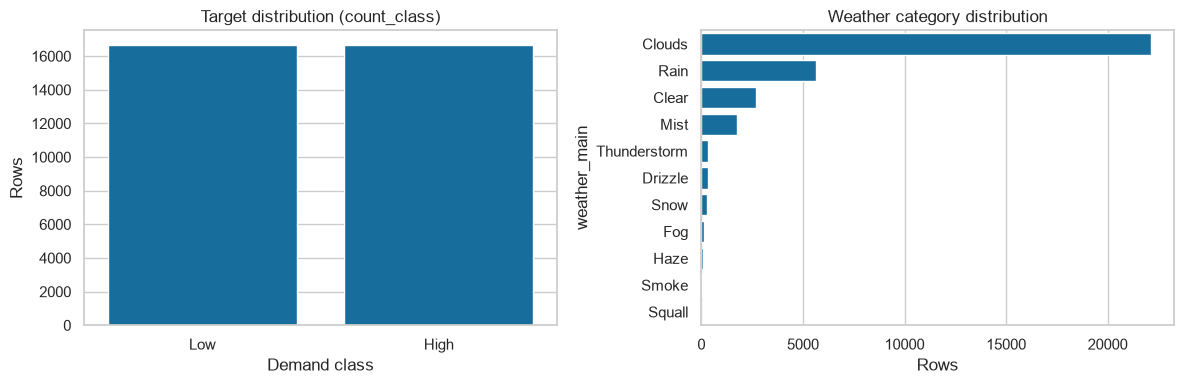

In [4]:
# 2c. Target distribution
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x='count_class', data=df, ax=ax[0])
ax[0].set_title('Target distribution (count_class)'); ax[0].set_xlabel('Demand class'); ax[0].set_ylabel('Rows')
sns.countplot(y='weather_main', data=df, order=df['weather_main'].value_counts().index, ax=ax[1])
ax[1].set_title('Weather category distribution'); ax[1].set_xlabel('Rows'); ax[1].set_ylabel('weather_main')
plt.tight_layout(); plt.show()

> **Observation 2c: class and weather balance.**
> - The two demand classes are **equal in size**, so we do not need any balancing.
> - Weather types are **not balanced**. Clouds is about two thirds of the data, then Rain and Clear. Types like Thunderstorm, Drizzle, Snow, Fog, Haze, Smoke and Squall have very few rows, so a cluster for them will be small.

### 2d. Features vs demand

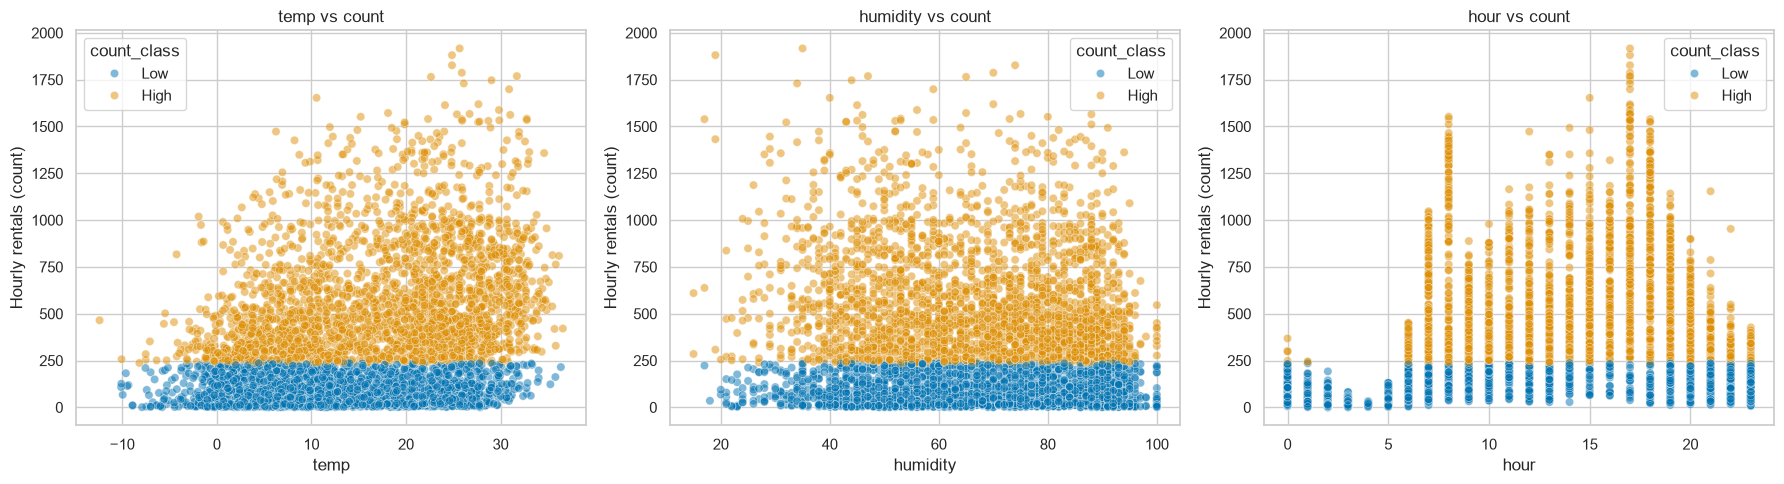

In [5]:
# 2d. Feature-target scatter plots
tmp = df.assign(hour=df['datetime'].dt.hour)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, c in zip(axes, ['temp', 'humidity', 'hour']):
    sns.scatterplot(data=tmp.sample(5000, random_state=RANDOM_STATE), x=c, y='count',
                    hue='count_class', alpha=.5, ax=ax)
    ax.set_title(f'{c} vs count'); ax.set_xlabel(c); ax.set_ylabel('Hourly rentals (count)')
plt.tight_layout(); plt.show()

> **Observation 2d: what affects demand.**
> - **Temperature:** High demand hours are rare when it is very cold (below about 0 °C). Above about 10 °C demand goes higher and is more spread out. So warm weather allows high demand but does not guarantee it.
> - **Humidity:** no clear pattern. High and Low points are mixed everywhere.
> - **Hour of day:** this is the **strongest pattern**. Demand is low at night, rises from 6 am, and has peaks at **8 am and 5 to 6 pm** (office hours).
> - Since hour of day matters so much, we expect weather clusters to match High / Low demand only partly. We test this in Section 9.

---

<a id="s3"></a>
## Section 3: Cleaning

In this section we clean the data so that the clustering algorithms work properly, without losing any rows.

| Problem | What we did |
|:--|:--|
| Duplicate rows | Dropped (none found) and sorted by `datetime` |
| Blank `rain_1h` / `snow_1h` | Filled with 0 (nothing was recorded) |
| Very large values in `wind_speed`, `rain_1h`, `snow_1h` | Capped at the 99.9th percentile (all rows kept) |

First we check outliers using the IQR rule on the recorded values only.

In [6]:
df_clean = df.drop_duplicates().sort_values('datetime').reset_index(drop=True)

# Outlier check (IQR rule) on RECORDED values only (blank rain/snow = nothing recorded)
def iqr_outliers(s):
    s = s.dropna()
    q1, q3 = s.quantile(.25), s.quantile(.75); iqr = q3 - q1
    n = ((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum()
    return pd.Series({'n_outliers': n, 'percent': round(n / len(s) * 100, 2)})

chk_cols = ['temp','pressure','humidity','wind_speed','rain_1h','snow_1h','clouds_all']
print("IQR outliers per column:\n", pd.DataFrame({c: iqr_outliers(df_clean[c]) for c in chk_cols}).T)

# rain_1h / snow_1h are NaN when no precipitation was recorded -> 0
df_clean[['rain_1h', 'snow_1h']] = df_clean[['rain_1h', 'snow_1h']].fillna(0)
print("\nMissing after cleaning:", df_clean.isna().sum().sum())

# Treatment: cap the extreme upper tail at the 99.9th percentile (keeps all rows)
for c in ['wind_speed', 'rain_1h', 'snow_1h']:
    df_clean[c] = df_clean[c].clip(upper=df_clean[c].quantile(.999))

IQR outliers per column:
             n_outliers  percent
temp               0.0     0.00
pressure         304.0     0.91
humidity           0.0     0.00
wind_speed      1099.0     3.29
rain_1h          661.0     9.76
snow_1h           10.0     3.07
clouds_all         0.0     0.00

Missing after cleaning: 0


> **Observation 3: outliers and missing values.**
> - `temp`, `humidity` and `clouds_all` have **no outliers**.
> - `rain_1h` has the most outliers (**9.76%**), then `wind_speed` (3.29%), `snow_1h` (3.07%) and `pressure` (0.91%). These are real weather events like storms and heavy rain, not mistakes, so we **cap them instead of deleting them**.
> - After cleaning there are **0 missing values** and all rows are kept.

---

<a id="s4"></a>
## Section 4: Feature Engineering

In this section we create new features that are suitable for clustering.

| New feature | Why we made it |
|:--|:--|
| `hour_sin`, `hour_cos` | Hour is a cycle, so 23:00 is close to 00:00 |
| `month_sin`, `month_cos` | Month is a cycle, so December is close to January |
| `wind_sin`, `wind_cos` | Wind direction is an angle, so 0° and 360° are the same |
| `is_precip` | 1 if there is rain or snow in that hour |
| `temp_feels_diff` | `feels_like - temp`, shows the effect of wind chill or heat |

We drop `temp_min`, `temp_max` and `feels_like` because they repeat `temp`. We also leave out `count` and `count_class` to **avoid label leakage**.

In [7]:
# Redundancy check: temperature columns
print(df_clean[['temp','feels_like','temp_min','temp_max']].corr().round(3))

d = df_clean['datetime']
df_fe = df_clean.copy()
df_fe['hour']  = d.dt.hour
df_fe['month'] = d.dt.month

# Cyclical encodings (23:00 is close to 00:00; December is close to January)
df_fe['hour_sin']  = np.sin(2*np.pi*df_fe['hour']/24);  df_fe['hour_cos']  = np.cos(2*np.pi*df_fe['hour']/24)
df_fe['month_sin'] = np.sin(2*np.pi*df_fe['month']/12); df_fe['month_cos'] = np.cos(2*np.pi*df_fe['month']/12)
# Wind direction is an angle (0 and 360 are the same)
df_fe['wind_sin'] = np.sin(np.deg2rad(df_fe['wind_deg'])); df_fe['wind_cos'] = np.cos(np.deg2rad(df_fe['wind_deg']))
# Other engineered features
df_fe['is_precip']       = ((df_fe['rain_1h'] > 0) | (df_fe['snow_1h'] > 0)).astype(int)
df_fe['temp_feels_diff'] = df_fe['feels_like'] - df_fe['temp']   # wind-chill / heat-index effect

# NOTE: 'count' and 'count_class' are deliberately excluded (label leakage).
# temp_min/temp_max/feels_like dropped: near-duplicates of temp (corr > 0.95) would over-weight temperature.
features = ['holiday','workingday','temp','temp_feels_diff','pressure','humidity','wind_speed',
            'wind_sin','wind_cos','rain_1h','snow_1h','clouds_all','is_precip',
            'hour_sin','hour_cos','month_sin','month_cos']
print(len(features), "clustering features")

             temp  feels_like  temp_min  temp_max
temp        1.000       0.994     0.995     0.998
feels_like  0.994       1.000     0.988     0.993
temp_min    0.995       0.988     1.000     0.992
temp_max    0.998       0.993     0.992     1.000
17 clustering features


> **Observation 4: repeated features and final feature set.**
> - The four temperature columns have a correlation of **0.988 to 0.998**, so they give the same information. We keep `temp` and the small `temp_feels_diff` only.
> - We end up with **17 features**: 2 day-type flags, 6 weather features (including the temperature gap), 3 rain / snow features and 6 sin / cos features (hour, month, wind direction).

---

<a id="s5"></a>
## Section 5: Encoding, Scaling, Splitting, PCA Structure

In this section we prepare the data for the models and check its structure with PCA.

- **Encoding:** `holiday` and `workingday` are already 0 / 1. `weather_main` and `count_class` are kept only for checking the results.
- **Splitting:** 80% train and 20% test, with the same class ratio in both.
- **Scaling:** `StandardScaler` is fitted on the **training data only** and then applied to the test data.
- **Sample:** we use 8,000 training rows for all models, because hierarchical clustering is very slow on large data. Using the same rows for every model keeps the comparison fair.
- **PCA:** we plot the cumulative explained variance to see how much structure the data has.

(26703, 17) (6676, 17) (8000, 17)


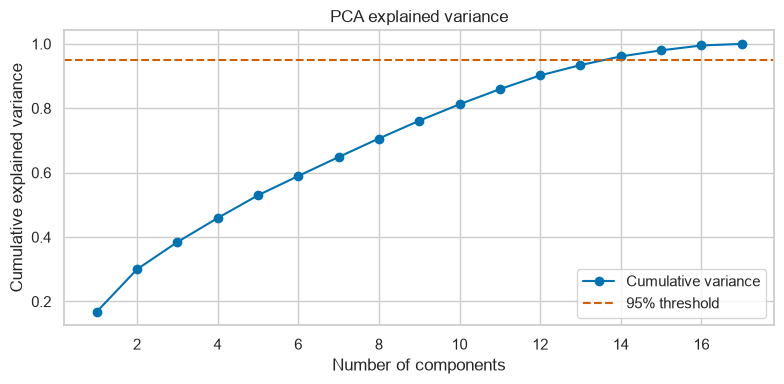

Components for 95% variance: 14


In [8]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Categoricals: holiday/workingday are already 0/1; weather_main and count_class are kept
# only as external validation labels (not features).
X, y = df_fe[features], df_fe['count_class']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

scaler = StandardScaler().fit(X_train)          # fit on TRAIN only (no leakage)
X_train_s = pd.DataFrame(scaler.transform(X_train), columns=features, index=X_train.index)
X_test_s  = pd.DataFrame(scaler.transform(X_test),  columns=features, index=X_test.index)

# Working sample for all clustering/metrics (same rows for every algorithm)
N_SAMPLE = 8000
samp_idx = X_train_s.sample(N_SAMPLE, random_state=RANDOM_STATE).index
X_samp   = X_train_s.loc[samp_idx]
raw_samp = df_fe.loc[samp_idx]                  # unscaled features + labels, for profiling
print(X_train_s.shape, X_test_s.shape, X_samp.shape)

# PCA structure
pca_full = PCA(random_state=RANDOM_STATE).fit(X_train_s)
cum = np.cumsum(pca_full.explained_variance_ratio_)
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cum)+1), cum, marker='o', label='Cumulative variance')
plt.axhline(.95, color='r', ls='--', label='95% threshold')
plt.title('PCA explained variance'); plt.xlabel('Number of components'); plt.ylabel('Cumulative explained variance')
plt.legend(); plt.tight_layout(); plt.show()
print("Components for 95% variance:", int(np.argmax(cum >= .95)) + 1)

> **Observation 5: shapes and PCA.**
> - After splitting we have **26,703 training rows** and **6,676 test rows**. The sample has **8,000 rows and 17 features**.
> - The PCA curve goes up slowly and **14 out of 17 components** are needed to reach 95% variance. So the information is spread over many directions and cannot be squeezed into a few.
> - This tells us that clusters will probably **overlap** and the scores will not be very high.

---

<a id="s6"></a>
## Section 6: K-Means and Agglomerative Clustering

In this section we choose the number of clusters and fit both algorithms on the same sample.

### 6a. K-Means: elbow and silhouette for k = 2 to 10

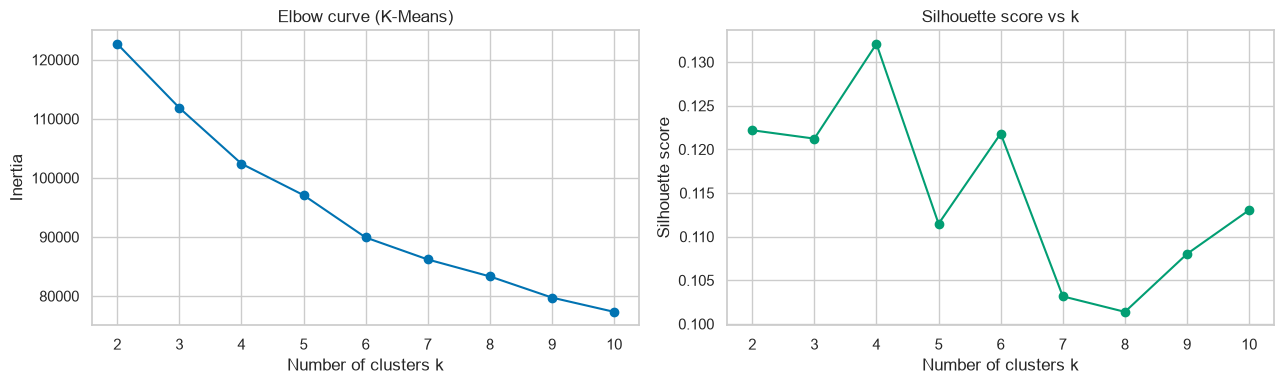

Chosen k = 4


In [9]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# 6a. K-Means: elbow + silhouette for k = 2..10
ks, inertias, sils = list(range(2, 11)), [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_samp)
    inertias.append(km.inertia_); sils.append(silhouette_score(X_samp, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(ks, inertias, marker='o'); ax[0].set_title('Elbow curve (K-Means)')
ax[0].set_xlabel('Number of clusters k'); ax[0].set_ylabel('Inertia')
ax[1].plot(ks, sils, marker='o', color='C2'); ax[1].set_title('Silhouette score vs k')
ax[1].set_xlabel('Number of clusters k'); ax[1].set_ylabel('Silhouette score')
plt.tight_layout(); plt.show()

# Default = best silhouette. Override after looking at the elbow, e.g. K = 4
K = ks[int(np.argmax(sils))]
print("Chosen k =", K)

km_final  = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X_samp)
labels_km = km_final.labels_

> **Observation 6a: choosing k.**
> - The **elbow curve** goes down smoothly and there is only a small bend around k = 4 to 6, so the elbow alone is not very clear.
> - The **silhouette score is highest at k = 4 (about 0.132)**, and it is lower for all other values of k.
> - Both plots support **k = 4**, so we use 4 clusters. The silhouette value is low, which shows the clusters overlap a bit.

### 6b. Dendrogram (Ward linkage)

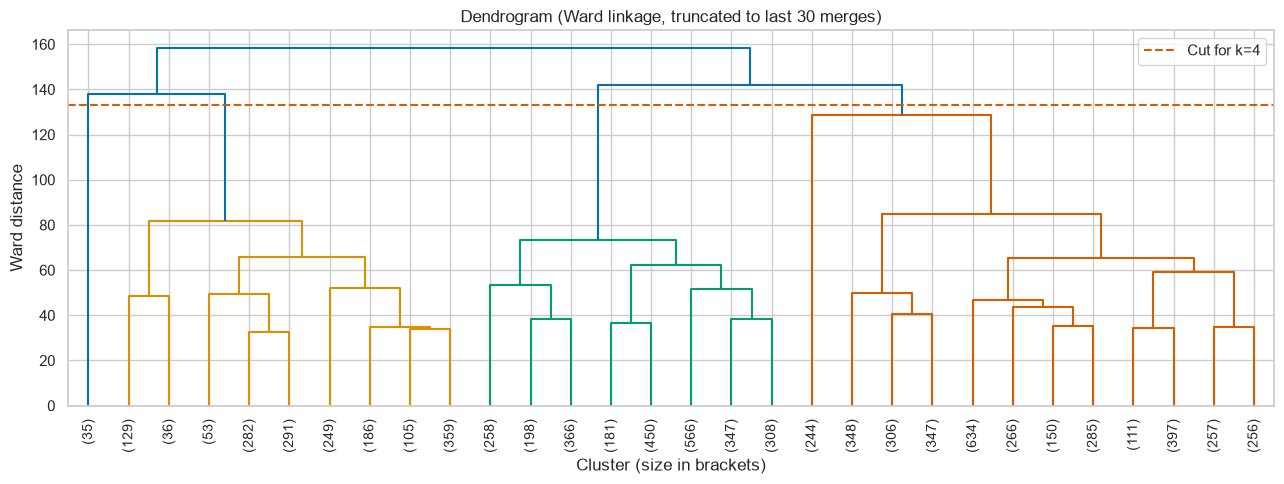

In [10]:
# 6b. Dendrogram (Ward) on the sample
from scipy.cluster.hierarchy import linkage, dendrogram
Z = linkage(X_samp.values, method='ward')
cut = (Z[-K, 2] + Z[-(K-1), 2]) / 2            # height that yields K clusters

plt.figure(figsize=(13, 5))
dendrogram(Z, truncate_mode='lastp', p=30, show_leaf_counts=True, leaf_rotation=90, color_threshold=cut)
plt.axhline(cut, color='r', ls='--', label=f'Cut for k={K}')
plt.title('Dendrogram (Ward linkage, truncated to last 30 merges)')
plt.xlabel('Cluster (size in brackets)'); plt.ylabel('Ward distance'); plt.legend()
plt.tight_layout(); plt.show()

> **Observation 6b: dendrogram.**
> - The last merges happen at high distances (about 140 to 160), so the data splits into a few big groups.
> - The dashed line is the cut for **k = 4**. It separates a **very small group on the left (35 points)** and splits the rest into three bigger groups.
> - Below the cut line the merge heights go down fairly gradually, so the data changes slowly and the groups are not sharply separated.

### 6c. Comparing linkages at k = 4

In [11]:
# 6c. Compare linkage strategies at k = K
rows = []
for link in ['ward', 'complete', 'average', 'single']:
    lab = AgglomerativeClustering(n_clusters=K, linkage=link).fit_predict(X_samp)
    rows.append({'Linkage': link,
                 'Silhouette': silhouette_score(X_samp, lab),
                 'Davies-Bouldin': davies_bouldin_score(X_samp, lab),
                 'Calinski-Harabasz': calinski_harabasz_score(X_samp, lab),
                 'Min cluster %': np.bincount(lab).min() / len(lab) * 100})
link_df = pd.DataFrame(rows).set_index('Linkage').round(3)
display(link_df)

# Pick best silhouette among non-degenerate solutions (smallest cluster >= 2%)
valid = link_df[link_df['Min cluster %'] >= 2]
BEST_LINK = valid['Silhouette'].idxmax() if len(valid) else 'ward'
print("Selected linkage:", BEST_LINK)
labels_agg = AgglomerativeClustering(n_clusters=K, linkage=BEST_LINK).fit_predict(X_samp)

,Silhouette,Davies-Bouldin,Calinski-Harabasz,Min cluster %
Linkage,,,,
ward,0.099,2.005,801.995,0.438
complete,0.332,0.912,343.240,0.350
average,0.427,0.784,303.021,0.125
single,0.325,0.789,178.505,0.012


Selected linkage: ward


> **Observation 6c: linkage comparison.**
> - Complete, average and single linkage have **higher silhouette scores (0.33 to 0.43)**, but this is misleading. Their smallest clusters have only **0.35%, 0.125% and 0.012%** of the data (about 28, 10 and 1 points). They just pick a few outliers and put everything else in one big cluster.
> - **Ward** has a lower silhouette (0.099) but gives the **most balanced clusters** and the best Calinski-Harabasz score (802).
> - Our rule rejects any result whose smallest cluster is below 2% of the data. All four linkages are below this (Ward's smallest cluster has 35 rows. It sits in the same place as the K-Means snowy cluster in the PCA plot, so it looks like a real group and not a single outlier), so the code selects **Ward** by default. Ward is also close to the way K-Means works.

---

<a id="s7"></a>
## Section 7: Comparative Evaluation

In this section we compare K-Means and Agglomerative clustering using different measures.

| Metric | Better when | What it tells us |
|:--|:--:|:--|
| Silhouette | higher | How well points fit their own cluster compared to other clusters |
| Davies-Bouldin | lower | How similar each cluster is to its closest cluster |
| Calinski-Harabasz | higher | Difference between clusters compared to spread inside clusters |
| Stability (ARI) | higher | How similar the labels stay when we use 80% subsamples (5 repeats) |
| Silhouette on test data | higher | Whether K-Means also works on unseen rows |

In [12]:
from sklearn.metrics import adjusted_rand_score

def metrics(X_, lab):
    return {'Silhouette (↑)': silhouette_score(X_, lab),
            'Davies-Bouldin (↓)': davies_bouldin_score(X_, lab),
            'Calinski-Harabasz (↑)': calinski_harabasz_score(X_, lab)}

def stability(model_fn, X_, ref, n_rep=5, frac=.8):
    """Mean ARI between full-sample labels and labels from 80% subsamples."""
    rng, sc = np.random.RandomState(RANDOM_STATE), []
    for i in range(n_rep):
        idx = rng.choice(len(X_), int(frac*len(X_)), replace=False)
        sc.append(adjusted_rand_score(ref[idx], model_fn(i).fit_predict(X_.iloc[idx])))
    return np.mean(sc), np.std(sc)

st_km  = stability(lambda i: KMeans(K, n_init=10, random_state=i), X_samp, labels_km)
st_agg = stability(lambda i: AgglomerativeClustering(n_clusters=K, linkage=BEST_LINK), X_samp, labels_agg)

results = pd.DataFrame({'K-Means': metrics(X_samp, labels_km),
                        f'Agglomerative ({BEST_LINK})': metrics(X_samp, labels_agg)}).T
results['Stability ARI (mean)'] = [st_km[0], st_agg[0]]
results['Stability ARI (std)']  = [st_km[1], st_agg[1]]
results['Agreement ARI (KM vs Agg)'] = adjusted_rand_score(labels_km, labels_agg)
display(results.round(3))

# Generalisation: assign unseen test rows with the fitted K-Means
test_lab = km_final.predict(X_test_s)
print("K-Means silhouette on held-out test (4000 rows):",
      round(silhouette_score(X_test_s.sample(4000, random_state=RANDOM_STATE),
                             pd.Series(test_lab, index=X_test_s.index).loc[X_test_s.sample(4000, random_state=RANDOM_STATE).index]), 3))

,Silhouette (↑),Davies-Bouldin (↓),Calinski-Harabasz (↑),Stability ARI (mean),Stability ARI (std),Agreement ARI (KM vs Agg)
K-Means,0.132,1.810,945.259,0.903,0.117,0.613
Agglomerative (ward),0.099,2.005,801.995,0.675,0.036,0.613


K-Means silhouette on held-out test (4000 rows): 0.135


> **Observation 7: comparing the models.**
>
> | Metric | K-Means | Agglomerative (Ward) |
> |:--|:--:|:--:|
> | Silhouette | **0.132** | 0.099 |
> | Davies-Bouldin | **1.810** | 2.005 |
> | Calinski-Harabasz | **945.3** | 802.0 |
> | Stability ARI (mean) | **0.903** | 0.675 |
> | Stability ARI (std) | 0.117 | **0.036** |
>
> - K-Means is better in all three internal metrics and has higher mean stability, so it is the **better model** here. Ward has a smaller std, so its results vary less between repeats.
> - The two methods agree **moderately** (ARI = 0.613). They find similar groups but draw the boundaries differently.
> - On the test data the K-Means silhouette is **0.135**, almost the same as on training data, so the clusters **work on new data too**.
> - All silhouette values are below 0.15, so the clusters **overlap**. This is because of the data (see Section 5) and not only the algorithm.

---

<a id="s8"></a>
## Section 8: Cluster Visualisation

In this section we draw the clusters in 2D using PCA and t-SNE.

> The cluster numbers are random and **different for each algorithm**. For example, Ward's cluster 1 is roughly the same as K-Means cluster 0.

### 8a. PCA 2D

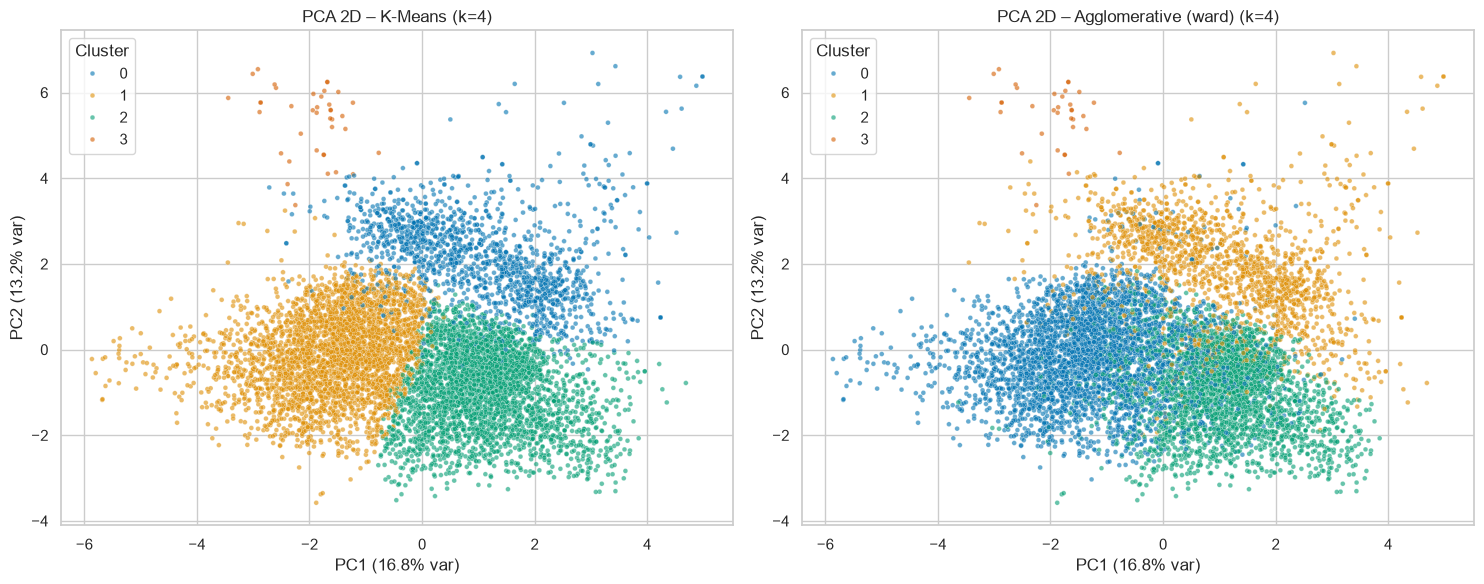

In [13]:
from sklearn.manifold import TSNE

# PCA 2D (fit on train, applied to sample)
pca2 = PCA(n_components=2, random_state=RANDOM_STATE).fit(X_train_s)
P = pca2.transform(X_samp)
ev = pca2.explained_variance_ratio_ * 100

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for a, lab, name in zip(ax, [labels_km, labels_agg], ['K-Means', f'Agglomerative ({BEST_LINK})']):
    sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=lab, palette='colorblind', s=12, alpha=.6, ax=a)
    a.set_title(f'PCA 2D – {name} (k={K})')
    a.set_xlabel(f'PC1 ({ev[0]:.1f}% var)'); a.set_ylabel(f'PC2 ({ev[1]:.1f}% var)')
    a.legend(title='Cluster')
plt.tight_layout(); plt.show()

> **Observation 8a: PCA plot.**
> - PC1 and PC2 explain only **about 30% of the variance** (16.8% + 13.2%), so a lot of information is hidden and the clusters overlap.
> - **K-Means** gives fairly clear areas: a left group, a right group, a top group and a small separate group at the top-left (snowy hours). The line between the left and right groups is straight, which is normal for K-Means.
> - **Ward** gives the same top group and small group, but its two big clusters **overlap more** in the middle. This matches its lower silhouette score.

### 8b. t-SNE

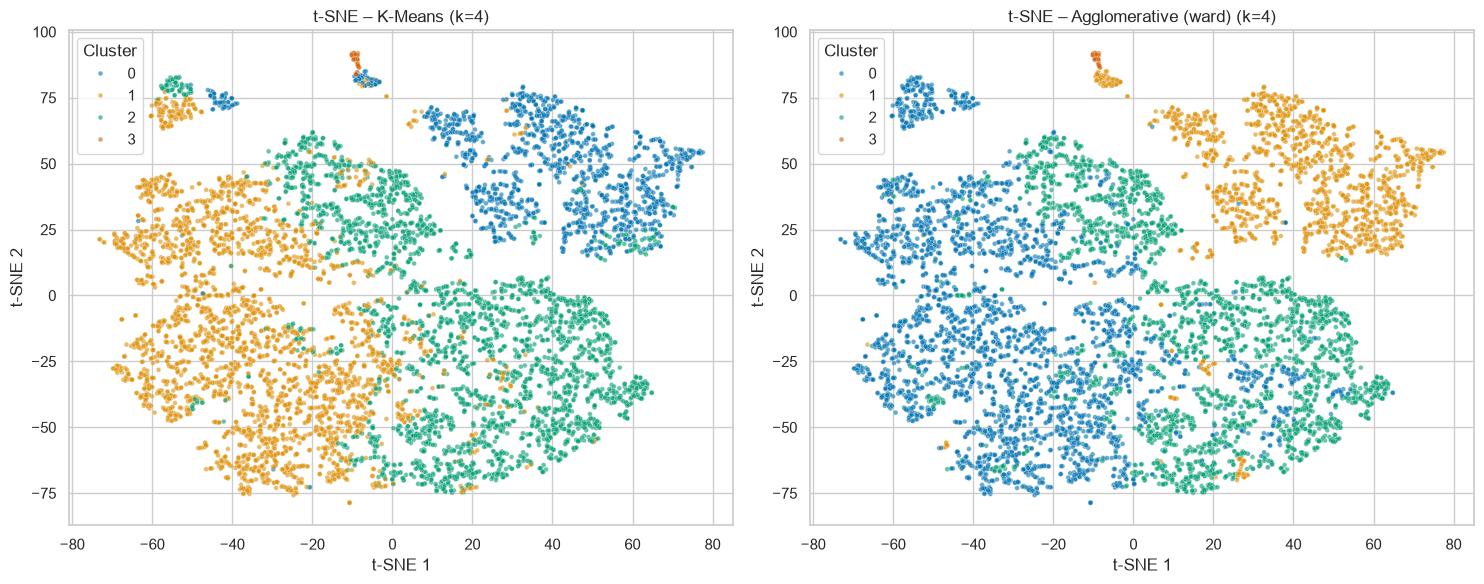

In [14]:
# t-SNE (takes ~1 min for 8,000 points)
T = TSNE(n_components=2, perplexity=30, init='pca', learning_rate='auto',
         random_state=RANDOM_STATE).fit_transform(X_samp)

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for a, lab, name in zip(ax, [labels_km, labels_agg], ['K-Means', f'Agglomerative ({BEST_LINK})']):
    sns.scatterplot(x=T[:, 0], y=T[:, 1], hue=lab, palette='colorblind', s=12, alpha=.6, ax=a)
    a.set_title(f't-SNE – {name} (k={K})'); a.set_xlabel('t-SNE 1'); a.set_ylabel('t-SNE 2')
    a.legend(title='Cluster')
plt.tight_layout(); plt.show()

> **Observation 8b: t-SNE plot.**
> - t-SNE shows a **big separate group at the top right** (the rain cluster) and **a few very small separate groups at the top** (one of them is the snowy cluster).
> - The two big groups at the bottom touch each other with no gap. They are the **cold and dry** hours and the **warm and dry** hours. Temperature changes slowly from one to the other, so K-Means is **cutting one continuous group into two** and not separating two natural groups.
> - Both algorithms find almost the same small groups. They differ mostly in where they cut the big group.

---

<a id="s9"></a>
## Section 9: Cluster Profiling and External Validation

In this section we find out what each K-Means cluster means in real units. Then we compare the clusters with `count_class` and `weather_main`. These labels were **never used to make the clusters**.

### 9a. Profile in original units

In [15]:
from sklearn.metrics import (normalized_mutual_info_score, homogeneity_score,
                             completeness_score, v_measure_score)

prof = raw_samp[features + ['count']].assign(Cluster=labels_km)

# 9a. Profile (original units)
display(prof.groupby('Cluster').mean().round(2).T)

Cluster,0,1,2,3
holiday,0.04,0.04,0.02,0.00
workingday,0.66,0.67,0.71,0.67
temp,14.47,7.02,24.15,-0.67
temp_feels_diff,-0.03,-1.28,0.81,-1.54
pressure,1013.25,1020.24,1015.42,1023.05
humidity,85.56,59.78,67.33,87.00
wind_speed,1.81,1.90,1.80,1.49
wind_sin,0.18,-0.16,-0.01,0.47
wind_cos,0.20,0.24,-0.15,0.36
rain_1h,1.21,0.00,0.01,0.00


> **Observation 9a: cluster profile table.**
>
> | Cluster | Mean temp | Humidity | Rain / snow | Mean demand |
> |:--:|:--:|:--:|:--|:--:|
> | 0 | 14.5 °C | 85.6% | Precipitation in almost every row (rain, 1.21 mm on average) | 228 |
> | 1 | 7.0 °C | 59.8% | Almost none (1% of rows) | 281 |
> | 2 | 24.2 °C | 67.3% | Almost none (3% of rows) | **445** |
> | 3 | -0.7 °C | 87.0% | Precipitation in every row (snow, 1.04 mm on average) | **61** |
>
> The four clusters are four types of weather: rainy and mild, cold and dry, warm and dry, and snowy and freezing. The holiday and working-day values are similar in all clusters, so day type does not decide the clusters.

### 9b. Standardised profile heatmap

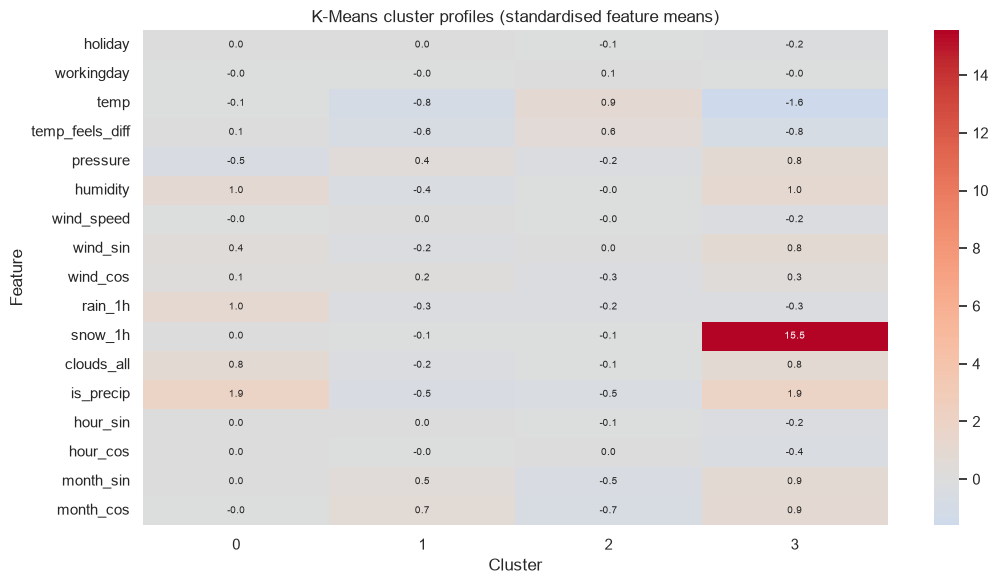

In [15]:
# 9b. Standardised profile heatmap
zprof = X_samp.assign(Cluster=labels_km).groupby('Cluster').mean()
plt.figure(figsize=(11, 6))
sns.heatmap(zprof.T, cmap='coolwarm', center=0, annot=True, fmt='.1f', annot_kws={'size': 7})
plt.title('K-Means cluster profiles (standardised feature means)'); plt.xlabel('Cluster'); plt.ylabel('Feature')
plt.tight_layout(); plt.show()

> **Observation 9b: what separates the clusters.**
> - **Cluster 3** is mainly defined by `snow_1h` (standardised mean **+15.5**, the highest value), very low temperature (-1.6) and precipitation.
> - **Cluster 0** is defined by rain and moisture: `is_precip` (+1.9), `rain_1h` (+1.0), humidity (+1.0) and clouds (+0.8).
> - **Cluster 1** is cold and dry (temp -0.8, humidity -0.4). **Cluster 2** is warm (temp +0.9) and has summer-type month values (`month_cos` -0.7).
> - The **hour features are close to 0 in clusters 0, 1 and 2** (cluster 3 is a little lower, about -0.2 to -0.4). So the clusters are based mainly on weather, and each cluster has hours from most times of the day.

### 9c. Demand in each cluster

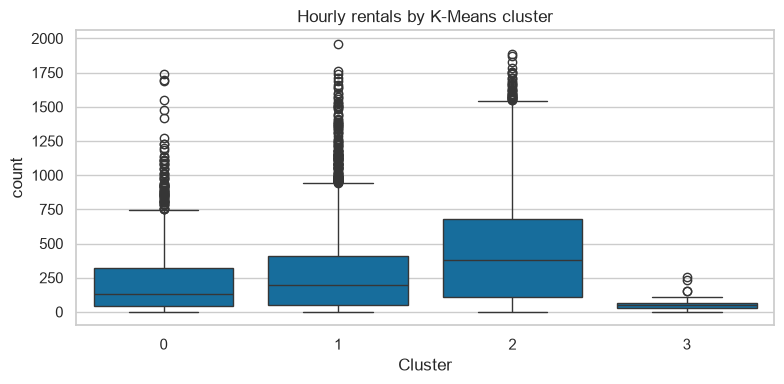

Cluster
0    134.0
1    197.0
2    380.5
3     53.0
Name: count, dtype: float64


In [15]:
# 9c. Demand per cluster
plt.figure(figsize=(8, 4))
sns.boxplot(x='Cluster', y='count', data=prof)
plt.title('Hourly rentals by K-Means cluster'); plt.xlabel('Cluster'); plt.ylabel('count')
plt.tight_layout(); plt.show()


# Median demand per cluster (complements the boxplot)
print(prof.groupby('Cluster')['count'].median())

> **Observation 9c: demand by cluster.**
> - The median hourly rentals are **134 (cluster 0), 197 (cluster 1), 380.5 (cluster 2) and 53 (cluster 3)**. Warm and dry weather has the highest demand, snow has the lowest, and rain also seems to reduce demand.
> - The boxes of clusters 0, 1 and 2 are wide with long upper tails (up to about 1,900 rides). This spread inside a cluster is because of the **hour of day** (Section 2d), which weather clusters do not capture.
> - Cluster 3 is very narrow and low (most hours below about 100 rides), so snow clearly reduces demand.

### 9d. Clusters vs demand class

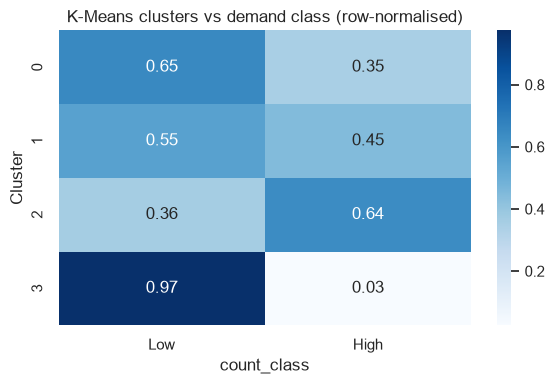

In [15]:
# 9d. External validation (labels used ONLY now)
ct = pd.crosstab(labels_km, raw_samp['count_class'], normalize='index')
plt.figure(figsize=(6, 4))
sns.heatmap(ct, annot=True, fmt='.2f', cmap='Blues')
plt.title('K-Means clusters vs demand class (row-normalised)'); plt.xlabel('count_class'); plt.ylabel('Cluster')
plt.tight_layout(); plt.show()

> **Observation 9d: link with High / Low demand.**
> - **Cluster 3 (snow) is 97% Low**, which is the clearest link.
> - **Cluster 2 (warm, dry) is 64% High** and **cluster 0 (rain) is 65% Low**.
> - **Cluster 1 (cold, dry) is almost equal (55% Low and 45% High)**, so it says little about demand.
> - The order of the clusters makes sense, but only clusters 2 and 3 are clearly useful. This is why the overall agreement scores below are low.

### 9e. External validation scores

In [15]:
ext = []
for algo, lab in [('K-Means', labels_km), (f'Agglomerative ({BEST_LINK})', labels_agg)]:
    for tname, tv in [('count_class', raw_samp['count_class']), ('weather_main', raw_samp['weather_main'])]:
        ext.append({'Algorithm': algo, 'Truth': tname,
                    'ARI': adjusted_rand_score(tv, lab), 'NMI': normalized_mutual_info_score(tv, lab),
                    'Homogeneity': homogeneity_score(tv, lab), 'Completeness': completeness_score(tv, lab),
                    'V-measure': v_measure_score(tv, lab)})
display(pd.DataFrame(ext).round(3))

,Algorithm,Truth,ARI,NMI,Homogeneity,Completeness,V-measure
0,K-Means,count_class,0.035,0.034,0.043,0.028,0.034
1,K-Means,weather_main,0.299,0.360,0.354,0.366,0.360
2,Agglomerative (ward),count_class,0.032,0.031,0.040,0.025,0.031
3,Agglomerative (ward),weather_main,0.293,0.352,0.346,0.357,0.352


> **Observation 9e: external validation.**
> - Agreement with **`weather_main`** is moderate (**NMI 0.36** for K-Means and 0.35 for Ward, ARI about 0.30). So the clusters find real weather types even though `weather_main` was not used as a feature.
> - Agreement with **`count_class`** is very low (**NMI 0.03** for both, ARI about 0.03). The High / Low label depends mostly on hour of day, which the weather clusters do not include.
> - K-Means is slightly better than Ward in every score, which matches Section 7.

---

<a id="s10"></a>
## Section 10: Conclusion

**Setup.** We clustered **17 scaled features** (weather and sin / cos time features) using an **8,000-row random sample** of the training data. `count` and `count_class` were not used for clustering, to avoid label leakage. They were used only for checking in Section 9.

**K-Means.** The elbow curve (no sharp bend) and the silhouette curve (clear peak) both support **k = 4**. Silhouette = **0.132**, Davies-Bouldin = **1.810**, Calinski-Harabasz = **945.3**. On unseen test rows the silhouette was **0.135**, so the clusters also work on new data.

**Agglomerative.** Complete, average and single linkage gave higher silhouettes (0.33 to 0.43), but their smallest clusters had only 0.35%, 0.125% and 0.012% of the data (about 28, 10 and 1 points). They just separate outliers and do not find real groups. So we used **Ward linkage**: Silhouette = **0.099**, Davies-Bouldin = **2.005**, Calinski-Harabasz = **802.0**.

**Comparison.**

| Metric | K-Means | Agglomerative (Ward) |
|:--|:--:|:--:|
| Silhouette (higher is better) | **0.132** | 0.099 |
| Davies-Bouldin (lower is better) | **1.810** | 2.005 |
| Calinski-Harabasz (higher is better) | **945.3** | 802.0 |
| Stability ARI, mean | **0.903** | 0.675 |
| Stability ARI, std | 0.117 | **0.036** |
| Agreement between methods (ARI) | 0.613 | 0.613 |

K-Means is better in all three internal metrics and in mean stability. Ward changes less between repeats (smaller std). The two methods agree moderately.

**Cluster meaning (K-Means).**

| Cluster | Weather type | Typical conditions | Median / mean demand | Low-demand hours |
|:--:|:--|:--|:--:|:--:|
| 0 | Rainy and mild | ~14.5 °C, rain in almost every row, humidity ~86%, cloudy | 134 / 228 | 65% |
| 1 | Cold and dry | ~7 °C, almost no rain or snow, lowest humidity (~60%) | 197 / 281 | 55% |
| 2 | Warm and dry | ~24 °C, almost no rain or snow, summer months | 380.5 / 445 | 36% |
| 3 | Snowy and freezing | ~-0.7 °C, snow in every row, humidity ~87%, cloudy | 53 / 61 | 97% |

**External validation.** The clusters match `weather_main` (NMI 0.36 for K-Means and 0.35 for Ward) but match the High / Low demand class only weakly (NMI 0.03 for both). The clusters are in a clear order by average demand (snowy lowest, warm and dry highest), but each cluster has hours from the whole day. So the High / Low label depends mostly on the **hour of day and day type**, and not on weather alone.

**Limitations.**
- Silhouette scores are low (about 0.10 to 0.14), so the clusters overlap. This matches PCA needing 14 components for 95% variance.
- The line between the cold-dry and warm-dry clusters cuts a smooth temperature change (see t-SNE in Section 8b).
- All four linkages had a cluster smaller than 2%. Ward's smallest cluster (35 rows) looks like the snowy-hours group, not a single outlier.
- We used a sample of 8,000 rows because hierarchical clustering is slow on large data.